In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Import the CSV datasets
df1 = pd.read_csv('data/fake_survey_dataset_1.csv')
df2 = pd.read_csv('data/fake_survey_dataset_2.csv')

In [2]:
# 2. Find the averages (mean) and standard deviations for each field in each dataframe
print("=== DATASET 1: MEANS & STANDARD DEVIATIONS ===")
stats_df1 = pd.DataFrame({
    'Mean': df1.mean(),
    'StdDev': df1.std()
})
print(stats_df1)

print("\n=== DATASET 2: MEANS & STANDARD DEVIATIONS ===")
stats_df2 = pd.DataFrame({
    'Mean': df2.mean(),
    'StdDev': df2.std()
})
print(stats_df2)

=== DATASET 1: MEANS & STANDARD DEVIATIONS ===
                     Mean    StdDev
BlameRobot           3.97  2.057040
BlameCompany         3.89  1.937900
BlameDeveloper       4.00  1.989873
CondemnRobot         3.87  2.223179
CondemnCompany       4.18  2.006958
CondemnDeveloper     4.10  1.935840
PunishRobot          3.91  1.907428
PunishCompany        3.77  1.984053
PunishDeveloper      3.78  2.086900
RobotIntentionality  4.11  1.953474
RobotWrongness       4.12  2.142782
InjuryLevel          4.03  1.935605

=== DATASET 2: MEANS & STANDARD DEVIATIONS ===
                     Mean    StdDev
BlameRobot           3.92  1.931556
BlameCompany         3.94  1.785576
BlameDeveloper       3.90  1.877566
CondemnRobot         4.45  1.950783
CondemnCompany       3.97  2.012361
CondemnDeveloper     3.74  1.987943
PunishRobot          4.11  1.943105
PunishCompany        4.02  2.093665
PunishDeveloper      4.14  2.025195
RobotIntentionality  3.85  1.876893
RobotWrongness       3.71  2.031544
Injur

In [3]:
# 3. Find the correlation between different fields
print("\n=== DATASET 1: CORRELATION MATRIX ===")
corr_df1 = df1.corr()
print(corr_df1)

print("\n=== DATASET 2: CORRELATION MATRIX ===")
corr_df2 = df2.corr()
print(corr_df2)


=== DATASET 1: CORRELATION MATRIX ===
                     BlameRobot  BlameCompany  BlameDeveloper  CondemnRobot  \
BlameRobot             1.000000      0.014367       -0.150531     -0.020740   
BlameCompany           0.014367      1.000000        0.075964      0.134976   
BlameDeveloper        -0.150531      0.075964        1.000000     -0.146132   
CondemnRobot          -0.020740      0.134976       -0.146132      1.000000   
CondemnCompany        -0.025593      0.067474       -0.032881      0.111700   
CondemnDeveloper      -0.034751     -0.104740        0.110133      0.073462   
PunishRobot           -0.095947      0.051948        0.154354     -0.045663   
PunishCompany          0.134415     -0.011901       -0.092106      0.013763   
PunishDeveloper       -0.058025      0.091364        0.021892      0.076505   
RobotIntentionality    0.028480      0.003229       -0.005197      0.003326   
RobotWrongness         0.133739     -0.111117        0.028428     -0.070905   
InjuryLevel  

In [4]:
# 4. Find the difference in means between Group 1 and Group 2
print("\n=== DIFFERENCE IN MEANS (Dataset 1 - Dataset 2) ===")
mean_diff = df1.mean() - df2.mean()
print(mean_diff)


=== DIFFERENCE IN MEANS (Dataset 1 - Dataset 2) ===
BlameRobot             0.05
BlameCompany          -0.05
BlameDeveloper         0.10
CondemnRobot          -0.58
CondemnCompany         0.21
CondemnDeveloper       0.36
PunishRobot           -0.20
PunishCompany         -0.25
PunishDeveloper       -0.36
RobotIntentionality    0.26
RobotWrongness         0.41
InjuryLevel           -0.36
dtype: float64



=== INDEPENDENT T-TEST RESULTS (Dataset 1 vs Dataset 2) ===
                     Mean_Diff  t_statistic   p_value
Field                                                
BlameRobot                0.05     0.177194  0.859538
BlameCompany             -0.05    -0.189746  0.849704
BlameDeveloper            0.10     0.365518  0.715116
CondemnRobot             -0.58    -1.960973  0.051308
CondemnCompany            0.21     0.738893  0.460847
CondemnDeveloper          0.36     1.297401  0.196004
PunishRobot              -0.20    -0.734523  0.463499
PunishCompany            -0.25    -0.866724  0.387145
PunishDeveloper          -0.36    -1.237957  0.217199
RobotIntentionality       0.26     0.959757  0.338350
RobotWrongness            0.41     1.388540  0.166537
InjuryLevel              -0.36    -1.312591  0.190840
=== FIELDS WITH P-VALUE < 0.20 ===
              Field  Dataset 1 Mean  Dataset 2 Mean   p_value
0      CondemnRobot            3.87            4.45  0.051308
1  CondemnDeveloper     

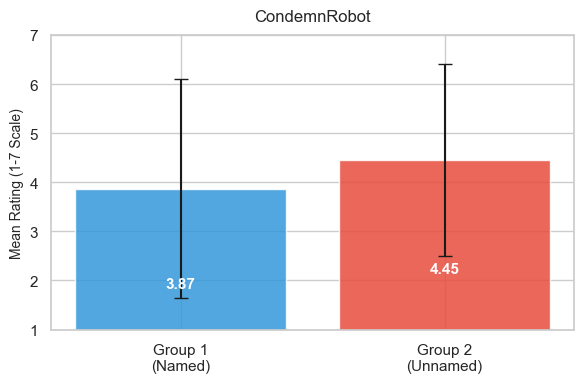

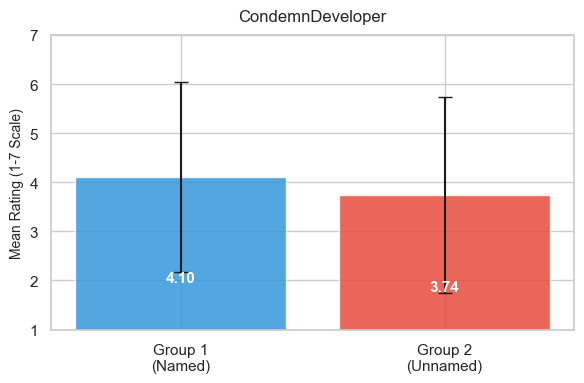

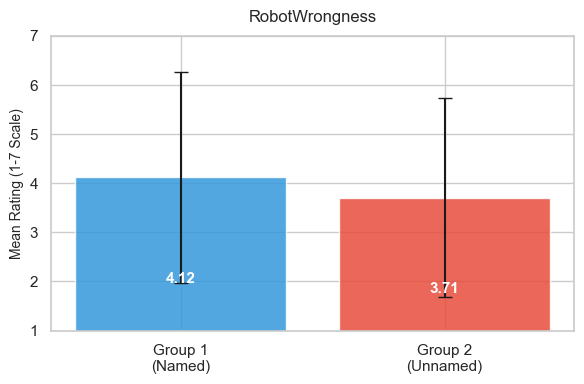

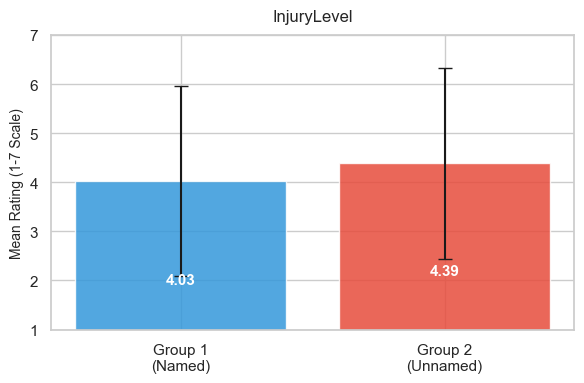

In [7]:
# Bonus: Independent samples t-test to determine if mean differences are statistically significant
print("\n=== INDEPENDENT T-TEST RESULTS (Dataset 1 vs Dataset 2) ===")
ttest_results = []
for col in df1.columns:
    t_stat, p_val = stats.ttest_ind(df1[col], df2[col], equal_var=False)
    ttest_results.append({
        'Field': col,
        'Mean_Diff': df1[col].mean() - df2[col].mean(),
        't_statistic': t_stat,
        'p_value': p_val
    })

ttest_df = pd.DataFrame(ttest_results).set_index('Field')
print(ttest_df)

ttest_results = []
for col in df1.columns:
    t_stat, p_val = stats.ttest_ind(df1[col], df2[col], equal_var=False)
    mean1 = df1[col].mean()
    mean2 = df2[col].mean()
    std1 = df1[col].std()
    std2 = df2[col].std()

    if p_val < 0.20:
        ttest_results.append({
            'Field': col,
            'Dataset 1 Mean': mean1,
            'Dataset 2 Mean': mean2,
            'Dataset 1 Std': std1,
            'Dataset 2 Std': std2,
            'p_value': p_val,
        })

filtered_df = pd.DataFrame(ttest_results)
print("=== FIELDS WITH P-VALUE < 0.20 ===")
print(filtered_df[['Field', 'Dataset 1 Mean', 'Dataset 2 Mean', 'p_value']])

# 3. Create a bar chart for each significant/marginal field
sns.set_theme(style='whitegrid')

for idx, row in filtered_df.iterrows():
    field = row['Field']

    plt.figure(figsize=(6, 4))
    means = [row['Dataset 1 Mean'], row['Dataset 2 Mean']]
    stds = [row['Dataset 1 Std'], row['Dataset 2 Std']]
    groups = ['Group 1\n(Named)', 'Group 2\n(Unnamed)']

    # Plot bars with standard error / standard deviation error bars
    bars = plt.bar(
        groups,
        means,
        yerr=stds,
        capsize=5,
        color=['#3498db', '#e74c3c'],
        alpha=0.85,
    )

    # Title and Labels
    plt.title(f'{field}', fontsize=12, pad=10)
    plt.ylabel('Mean Rating (1-7 Scale)', fontsize=10)
    plt.ylim(1, 7)

    # Add data values on top of bars
    for bar in bars:
        yval = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2.0,
            yval / 2,
            f'{yval:.2f}',
            ha='center',
            va='center',
            color='white',
            fontweight='bold',
            fontsize=11,
        )

    plt.tight_layout()
    plt.show()